# v9e: WIPE part of the self, then RELEARN (GPU 0)
**Question:** after the self is damaged, does the model get its performance back more slowly than after the same damage to look-alike task neurons?
- Start checkpoints: distant 30, 40; related 10, 15. Each relearns the language it was LAST trained on (the one it knows best).
- Wipe: 30% of each layer's working neurons get their incoming and outgoing weights re-drawn as at initialisation (they can learn again, unlike the lesion runs).
- Groups: nothing wiped / self / look-alike task / random task. Relearning: 1,000 steps, learning rate 3e-5, normal masked loss.
- Measured: held-out loss and chrF over relearning; other languages before vs after. 4 starts x 4 conditions x 3 seeds = 48 runs, seed 0 first.
Results: `analysis/v9/relearn/`. Progress: `tail -f logs/relearn_v9.log`.

In [1]:
import os, sys, glob, json, time, subprocess
os.environ["HF_HUB_DISABLE_XET"] = "1"
GPU = "0"
REPO = "/workspace/shreshth"; os.chdir(REPO); sys.path.insert(0, REPO)
from IPython.display import Image, display
from huggingface_hub import HfApi, hf_hub_download
for attempt in range(5):
    try:
        api = HfApi(); HF_REPO = api.whoami()["name"] + "/cml-lang-self-checkpoints"; FILES = api.list_repo_files(HF_REPO); break
    except Exception as e:
        print("HF retry", attempt, type(e).__name__); time.sleep(10)

def get(run, phases):
    for ph in phases:
        if glob.glob(f"runs/{run}/ckpt/p{ph:03d}_*.pt"):
            continue
        name = [f for f in FILES if f.startswith(f"{run}/ckpt/p{ph:03d}_")]
        if name:
            hf_hub_download(HF_REPO, name[0], local_dir="runs")
        else:
            print("missing (not here, not on HF):", run, ph)

def last_phase(run):
    phs = [int(os.path.basename(f)[1:4]) for f in FILES if f.startswith(f"{run}/ckpt/p")]
    phs += [int(os.path.basename(f)[1:4]) for f in glob.glob(f"runs/{run}/ckpt/p*.pt")]
    return max(phs)

def run(langset, *cmd):
    """runs one call, shows the output here AND appends it to logs/relearn_v9.log (watch with: tail -f logs/relearn_v9.log)"""
    env = {**os.environ, "CML_LANGSET": langset}; os.makedirs("logs", exist_ok=True)
    p = subprocess.Popen([sys.executable, "-u", "relearn_v9.py", "--gpu", GPU, *cmd], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env)
    with open("logs/relearn_v9.log", "a") as log:
        for line in p.stdout:
            print(line, end=""); log.write(line); log.flush()
    p.wait(); print("exit code", p.returncode)

DIST, REL = "v4b_continual_s0", "v8_indic_continual_s0"
STARTS = [("distant", DIST, 30), ("distant", DIST, 40), ("indic", REL, 10), ("indic", REL, 15)]
for _, r, ph in STARTS:
    get(r, [ph])
print("start models:", [(r, ph) for _, r, ph in STARTS])

/venv/main/lib/python3.12/site-packages/huggingface_hub/constants.py:302: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


start models: [('v4b_continual_s0', 30), ('v4b_continual_s0', 40), ('v8_indic_continual_s0', 10), ('v8_indic_continual_s0', 15)]


In [2]:
need = [f"data/en-{l}/train.jsonl" for l in ["hi", "zh", "gu"]] + [f"data/flores/devtest.{l}.jsonl" for l in ["en", "hi", "zh", "gu"]]
need += [f"data/flores/dev.{l}.jsonl" for l in ["en", "hi", "zh", "ar", "gu", "pa"]] + [f"data/en-{l}/val.jsonl" for l in ["hi", "zh", "ar", "gu", "pa"]]
miss = [f for f in need if not os.path.exists(f)]
print("all there" if not miss else f"MISSING: {miss}  -> run your download snippet first, then re-run this cell")

all there


In [3]:
for s in ["0", "1", "2"]:
    for langset, r, ph in STARTS:
        run(langset, "--start", f"{'distant' if langset == 'distant' else 'related'}{ph}={r}:{ph}", "--seeds", s)
    subprocess.run([sys.executable, "relearn_v9.py", "--summarize"])

start model: distant30 = v4b_continual_s0 phase 30 (last trained on ar) | language set distant: hi, zh, ar


  enc0.mlp: 2560 working neurons, self = 1234 (48%), switching off 768
  enc1.mlp: 2560 working neurons, self = 1189 (46%), switching off 768
  enc2.mlp: 2560 working neurons, self = 1224 (48%), switching off 768
  enc3.mlp: 2560 working neurons, self = 1538 (60%), switching off 768
  dec0.mlp: 2560 working neurons, self = 1482 (58%), switching off 768
  dec1.mlp: 2560 working neurons, self = 1325 (52%), switching off 768
  dec2.mlp: 2560 working neurons, self = 1394 (54%), switching off 768
  dec3.mlp: 2560 working neurons, self = 2049 (80%), switching off 768
  self found in 8s
  relearning ar: the language this checkpoint was last trained on


runs to do in this call: 4 (1 tasks x 4 conditions x seeds [0]; already done are skipped)


    dec3.mlp: self or task group too small, layer left intact


  loaded same: 300,000 train examples


  distant30 | same       | none      | seed 0 | loss 1.824 -> 1.847 | score 53.0 -> score 53.0 | 103s | left in this call: 3 runs, about 5 min


... (113 outputs left out)

  related15 | same       | random    | seed 2 | loss 2.080 -> 1.906 | score 42.9 -> score 43.4 | 102s | left in this call: 0 runs, about 0 min
done


exit code 0


=== v9: WIPE part of the self, then RELEARN the language the model knows best ===
one comparison = one start model x one seed: self wiped vs look-alike task neurons wiped (same number)
learning slowness = average held-out loss over the learning curve (steps 50 ... end); lower = learned faster

AVERAGE OVER SEEDS (curve loss | final score; score = accuracy % or chrF for Indonesian)
                          curve_loss  final_score  seeds
task start     cond                                     
same distant30 lookalike       1.983       51.499      3
               none            1.835       52.898      3
               random          1.973       51.303      3
               self            2.047       50.669      3
     distant40 lookalike       1.491       49.720      3
               none            1.241       51.579      3
               random          1.487       50.334      3
               self            1.619       48.680      3
     related10 lookalike       1.462       50.


figures + report in /workspace/shreshth/analysis/v9/relearn


=== v9: WIPE part of the self, then RELEARN the language the model knows best ===
one comparison = one start model x one seed: self wiped vs look-alike task neurons wiped (same number)
learning slowness = average held-out loss over the learning curve (steps 50 ... end); lower = learned faster

AVERAGE OVER SEEDS (curve loss | final score; score = accuracy % or chrF for Indonesian)
                          curve_loss  final_score  seeds
task start     cond                                     
same distant30 lookalike       1.983       51.499      3
               none            1.835       52.898      3
               random          1.973       51.303      3
               self            2.047       50.669      3
     distant40 lookalike       1.491       49.720      3
               none            1.241       51.579      3
               random          1.487       50.334      3
               self            1.619       48.680      3
     related10 lookalike       1.462       50.


figures + report in /workspace/shreshth/analysis/v9/relearn


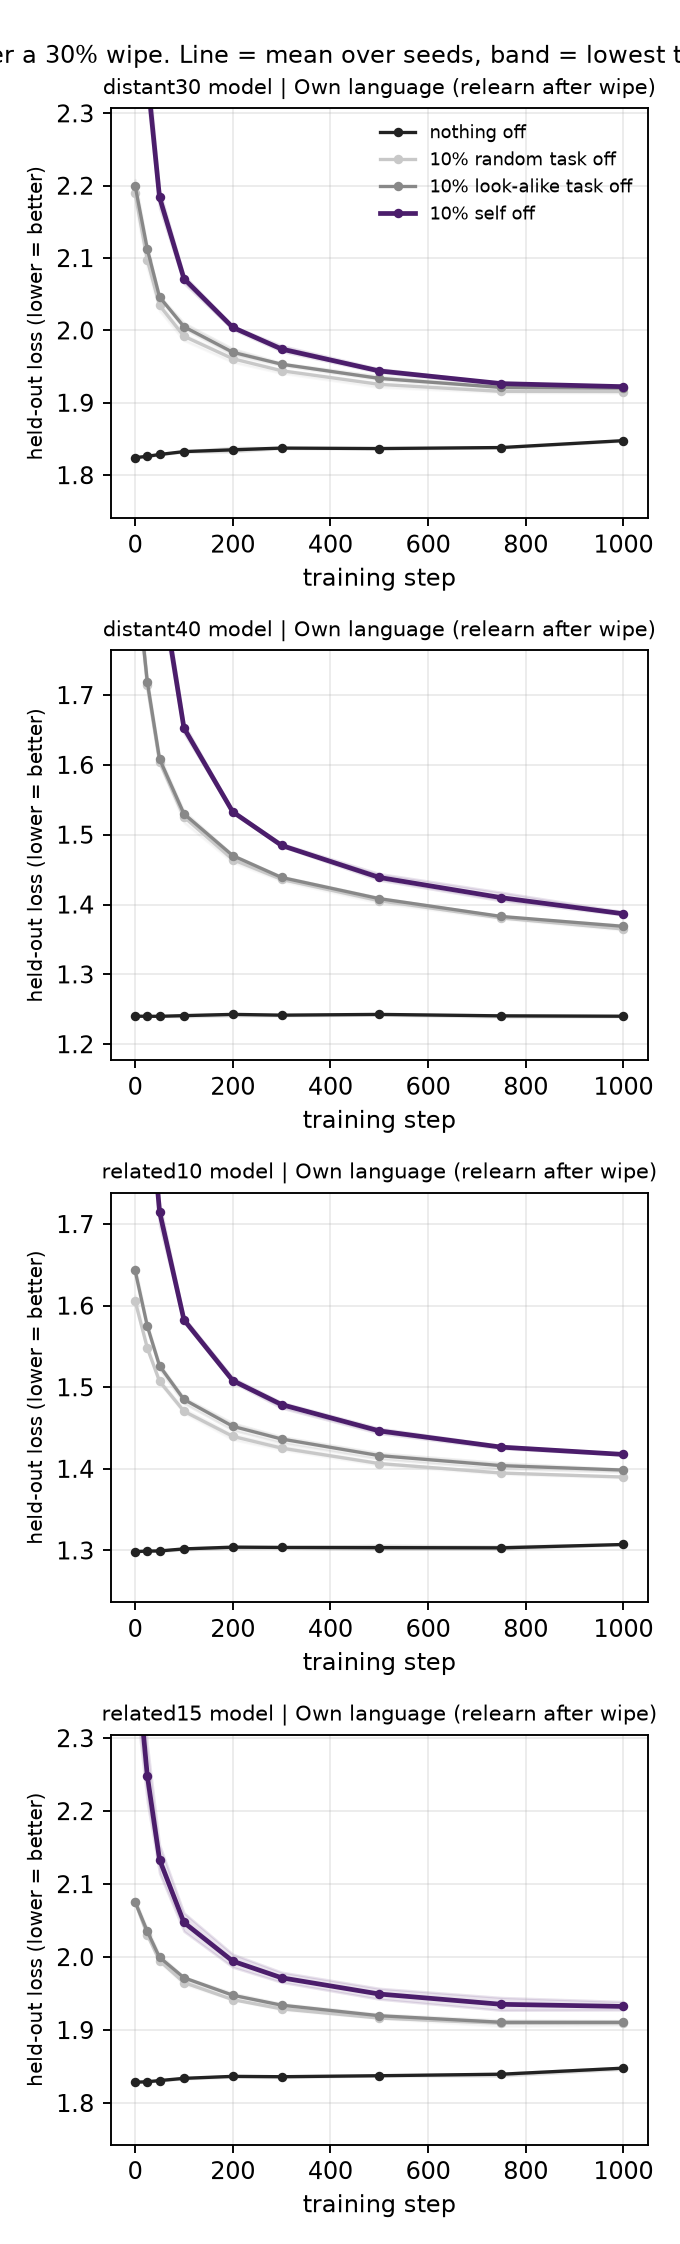

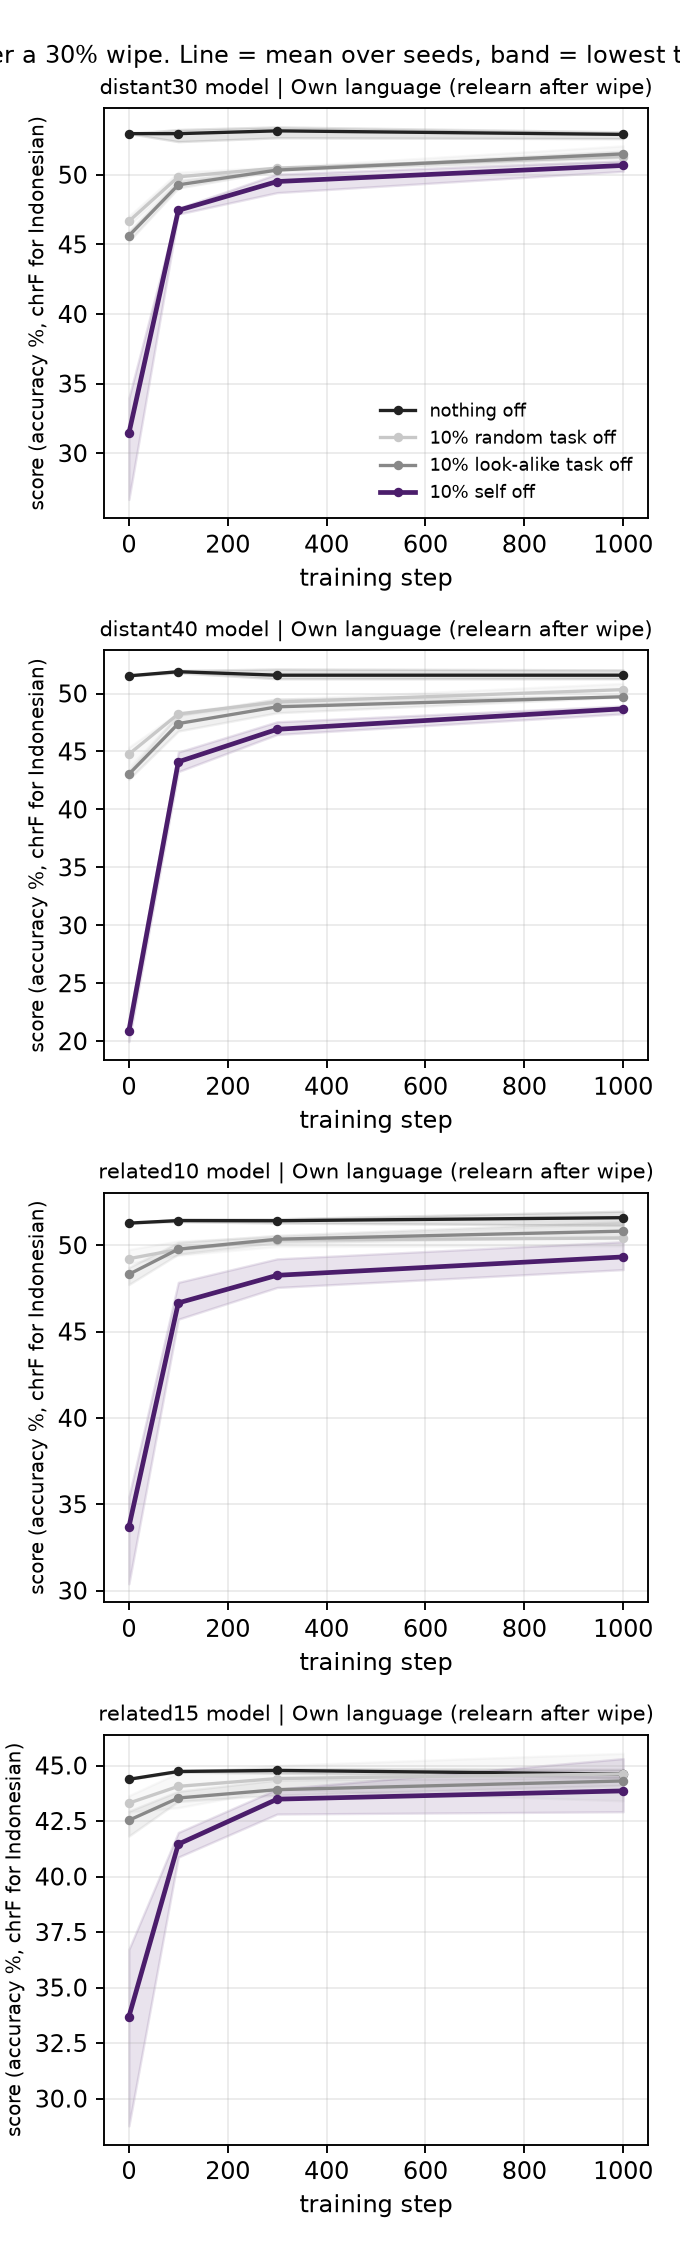

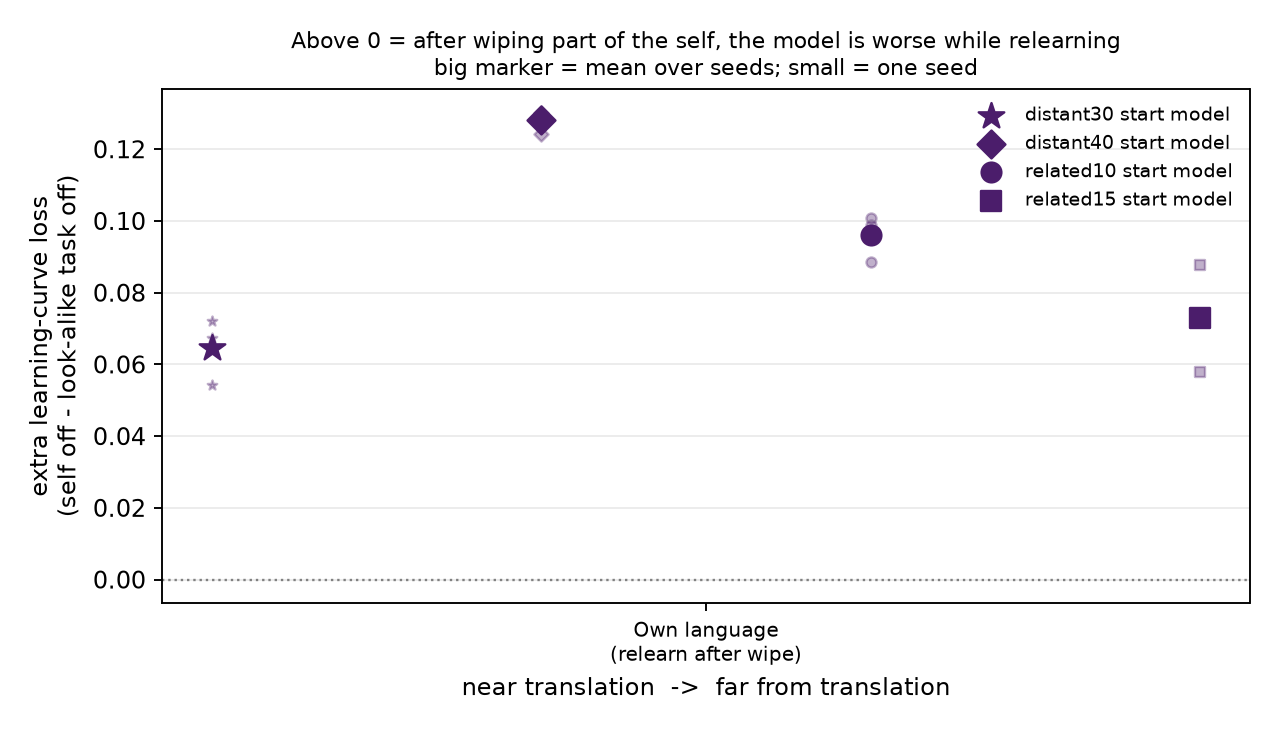

In [4]:
subprocess.run([sys.executable, "relearn_v9.py", "--summarize"])
for f in ["fig1_learning_curves_loss.png", "fig2_learning_curves_score.png", "fig3_near_to_far.png"]:
    display(Image(f"analysis/v9/relearn/{f}"))